In [12]:
import os
import pandas as pd
import numpy as np
import yfinance as yf
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import xgboost as xgb
from datetime import datetime, timedelta
from transformers import (
    AutoTokenizer, 
    AutoModelForSequenceClassification,
    TrainingArguments, 
    Trainer,
    DataCollatorWithPadding
)
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas_ta as ta

In [13]:
import warnings
warnings.filterwarnings("ignore")
os.environ["TRANSFORMERS_NO_TF"] = "1"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### 1. Data Loading and Preprocessing

In [14]:
# def load_indian_financial_news():
#     """Load and preprocess Indian financial news dataset"""
#     import kagglehub
#     path = kagglehub.dataset_download("hkapoor/indian-financial-news-articles-20032020")
#     csv_path = os.path.join(path, "IndianFinancialNews.csv")
#     news_df = pd.read_csv(csv_path, parse_dates=["Date"])
#     print(f"Loaded {len(news_df)} news articles")
#     return news_df
    
def load_indian_financial_news():
    """Load and preprocess 'therohk/india-headlines-news-dataset', filtered to business news."""
    import kagglehub  # Ensure kagglehub is installed and configured

    print("Downloading 'therohk/india-headlines-news-dataset'...")
    path = kagglehub.dataset_download("therohk/india-headlines-news-dataset")
    csv_path = os.path.join(path, "india-news-headlines.csv")

    # Load dataset with correct date parsing
    news_df = pd.read_csv(
        csv_path,
        parse_dates=["publish_date"],
        date_format='%Y%m%d'
    )
    print(f"Loaded {len(news_df)} total news articles.")

    # Filter business-related articles (relevant categories start with 'business')
    business_news_df = news_df[news_df['headline_category'].str.startswith('business', na=False)].copy()
    print(f"Filtered down to {len(business_news_df)} business-related articles.")

    # Rename columns for compatibility with existing pipeline
    business_news_df.rename(columns={'publish_date': 'Date', 'headline_text': 'Title'}, inplace=True)

    # Keep only necessary columns
    return business_news_df[['Date', 'Title']]
    
def create_nifty50_mapping():
    """Create mapping for NIFTY 50 companies"""
    return {
        "Adani Enterprises": "ADANIENT.NS", "Adani Ports": "ADANIPORTS.NS",
        "Apollo Hospitals": "APOLLOHOSP.NS", "Asian Paints": "ASIANPAINT.NS",
        "Axis Bank": "AXISBANK.NS", "Bajaj Auto": "BAJAJ-AUTO.NS",
        "Bajaj Finance": "BAJFINANCE.NS", "Bajaj Finserv": "BAJAJFINSV.NS",
        "Bharat Electronics": "BEL.NS", "Bharti Airtel": "BHARTIARTL.NS",
        "Cipla": "CIPLA.NS", "Coal India": "COALINDIA.NS",
        "Dr. Reddy": "DRREDDY.NS", "Eicher Motors": "EICHERMOT.NS",
        "Grasim Industries": "GRASIM.NS", "HCL Technologies": "HCLTECH.NS",
        "HDFC Bank": "HDFCBANK.NS", "HDFC Life": "HDFCLIFE.NS",
        "Hero MotoCorp": "HEROMOTOCO.NS", "Hindalco": "HINDALCO.NS",
        "Hindustan Unilever": "HINDUNILVR.NS", "ICICI Bank": "ICICIBANK.NS",
        "ITC": "ITC.NS", "IndusInd Bank": "INDUSINDBK.NS",
        "Infosys": "INFY.NS", "JSW Steel": "JSWSTEEL.NS",
        "Jio Financial": "JIOFIN.NS", "Kotak Mahindra Bank": "KOTAKBANK.NS",
        "Larsen & Toubro": "LT.NS", "M&M": "M&M.NS",
        "Maruti Suzuki": "MARUTI.NS", "NTPC": "NTPC.NS",
        "Nestle India": "NESTLEIND.NS", "ONGC": "ONGC.NS",
        "Power Grid": "POWERGRID.NS", "Reliance Industries": "RELIANCE.NS",
        "SBI Life": "SBILIFE.NS", "Shriram Finance": "SHRIRAMFIN.NS",
        "State Bank of India": "SBIN.NS", "Sun Pharma": "SUNPHARMA.NS",
        "TCS": "TCS.NS", "Tata Consumer": "TATACONSUM.NS",
        "Tata Motors": "TATAMOTORS.NS", "Tata Steel": "TATASTEEL.NS",
        "Tech Mahindra": "TECHM.NS", "Titan": "TITAN.NS",
        "Trent": "TRENT.NS", "UltraTech Cement": "ULTRACEMCO.NS",
        "Wipro": "WIPRO.NS"
    }

def detect_nifty_stock(title, nifty_50_map):
    """Detect which NIFTY 50 stock is mentioned in news title"""
    for company, ticker in nifty_50_map.items():
        if company.lower() in title.lower():
            return company, ticker
    return None, None

def preprocess_news_data():
    """Main preprocessing pipeline for news data"""
    news_df = load_indian_financial_news()
    nifty_50_map = create_nifty50_mapping()
    news_df[['Company', 'Ticker']] = news_df['Title'].apply(
        lambda t: pd.Series(detect_nifty_stock(t, nifty_50_map))
    )
    news_df = news_df.dropna(subset=['Ticker'])
    print(f"Filtered to {len(news_df)} articles for NIFTY 50 companies")
    print(f"Date range: {news_df['Date'].min()} to {news_df['Date'].max()}")
    # Group by Company: number of articles, min and max dates
    summary_df = news_df.groupby('Company').agg(
        no_of_articles=('Title', 'count'),
        min_date=('Date', 'min'),
        max_date=('Date', 'max')
    ).reset_index()

    # Format date columns for readable printing
    summary_df['min_date'] = summary_df['min_date'].dt.strftime('%Y-%m-%d')
    summary_df['max_date'] = summary_df['max_date'].dt.strftime('%Y-%m-%d')

    print("\nSummary by Company:")
    print(summary_df.to_string(index=False))
    return news_df

### 2. FinBERT Model Fine-Tuning

In [15]:
class FinBERTModelManager:
    AVAILABLE_MODELS = {
        "finbert-tone": "yiyanghkust/finbert-tone",
        "prosus-finbert": "ProsusAI/finbert",
        "finbert-esg": "yiyanghkust/finbert-esg"
    }
    
    def __init__(self, model_choice="finbert-tone"):
        self.model_name = self.AVAILABLE_MODELS.get(model_choice, model_choice)
        self.tokenizer = None
        self.model = None
        self.trained_model_path = None
    
    def load_base_model(self):
        print(f"Loading base model: {self.model_name}")
        self.tokenizer = AutoTokenizer.from_pretrained(self.model_name)
        self.model = AutoModelForSequenceClassification.from_pretrained(
            self.model_name, num_labels=3, trust_remote_code=False, use_safetensors=True
        ).to(device)
        return self.tokenizer, self.model
    
    def prepare_training_data(self):
        print("Loading Indian Financial News sentiment dataset...")
        dataset = load_dataset("kdave/Indian_Financial_News")
        label2id = {'Negative': 0, 'Neutral': 1, 'Positive': 2}
        id2label = {v: k for k, v in label2id.items()}
        
        def encode_labels(example):
            example["label"] = label2id[example["Sentiment"]]
            return example
        
        def tokenize(example):
            return self.tokenizer(
                example["Content"], padding="max_length", truncation=True, max_length=512
            )
        
        dataset = dataset.map(encode_labels)
        dataset = dataset.map(tokenize, batched=True)
        dataset.set_format(type='torch', columns=['input_ids', 'attention_mask', 'label'])
        return dataset, label2id, id2label
    
    def fine_tune_model(self, output_dir="./finbert-indian-sentiment", num_epochs=3, batch_size=16):
        dataset, label2id, id2label = self.prepare_training_data()
        self.model.config.id2label = id2label
        self.model.config.label2id = label2id
        
        training_args = TrainingArguments(
            output_dir=output_dir, eval_strategy="epoch", save_strategy="epoch",
            learning_rate=2e-5, per_device_train_batch_size=batch_size,
            per_device_eval_batch_size=32, num_train_epochs=num_epochs,
            weight_decay=0.01, logging_dir="./logs", logging_steps=10,
            load_best_model_at_end=True, metric_for_best_model="f1"
        )
        
        def compute_metrics(eval_pred):
            logits, labels = eval_pred
            predictions = logits.argmax(axis=-1)
            return {
                'accuracy': accuracy_score(labels, predictions),
                'f1': f1_score(labels, predictions, average='weighted'),
            }
        
        data_collator = DataCollatorWithPadding(tokenizer=self.tokenizer, return_tensors="pt")
        
        trainer = Trainer(
            model=self.model,
            args=training_args,
            train_dataset=dataset["train"].train_test_split(test_size=0.2)["train"],
            eval_dataset=dataset["train"].train_test_split(test_size=0.2)["test"],
            tokenizer=self.tokenizer,
            data_collator=data_collator,
            compute_metrics=compute_metrics
        )
        
        print("Starting fine-tuning...")
        trainer.train()
        trainer.save_model(output_dir)
        self.tokenizer.save_pretrained(output_dir)
        self.trained_model_path = output_dir
        print(f"Model saved to: {output_dir}")
        return trainer
    
    def load_trained_model(self, model_path):
        print(f"Loading trained model from: {model_path}")
        self.tokenizer = AutoTokenizer.from_pretrained(model_path)
        self.model = AutoModelForSequenceClassification.from_pretrained(model_path).to(device)
        self.model.eval()
        self.trained_model_path = model_path
        return self.tokenizer, self.model
    
    def get_sentiment(self, text):
        if self.tokenizer is None or self.model is None:
            raise ValueError("Model not loaded.")
        
        inputs = self.tokenizer(
            text, truncation=True, max_length=128, padding=True, return_tensors='pt'
        )
        inputs = {k: v.to(device) for k, v in inputs.items()}
        
        with torch.no_grad():
            outputs = self.model(**inputs)
            scores = torch.nn.functional.softmax(outputs.logits, dim=1).detach().cpu().numpy()[0]
        
        id2label = self.model.config.id2label
        label_order = [id2label[i] for i in range(len(id2label))]
        return {label: float(scores[i] * 100) for i, label in enumerate(label_order)}

### 3. Sentiment Analysis and Feature Engineering

In [16]:
def analyze_sentiment_with_model(news_df, model_manager):
    print("Analyzing sentiment for all news articles...")
    news_df["sentiment"] = news_df["Title"].apply(model_manager.get_sentiment)
    
    def extract_sentiment_label(sent_dict):
        return max(sent_dict, key=sent_dict.get) if isinstance(sent_dict, dict) else "unknown"
    
    news_df["sentiment_label"] = news_df["sentiment"].apply(extract_sentiment_label)
    return news_df

def create_sentiment_visualizations(news_df):
    plt.figure(figsize=(15, 6))
    stock_counts = news_df['Ticker'].value_counts()
    sns.barplot(x=stock_counts.index, y=stock_counts.values, palette="Blues_d")
    plt.title('Number of News Articles per Stock', fontsize=14, fontweight='bold')
    plt.xlabel('Stock Ticker')
    plt.ylabel('News Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    plt.figure(figsize=(15, 8))
    sentiment_dist = news_df.groupby(['Ticker', 'sentiment_label']).size().unstack(fill_value=0)
    sentiment_dist.plot(kind='bar', stacked=True, colormap='RdYlGn', ax=plt.gca())
    plt.title('Sentiment Distribution per Stock', fontsize=14, fontweight='bold')
    plt.xlabel('Stock Ticker')
    plt.ylabel('Number of Articles')
    plt.xticks(rotation=45)
    plt.legend(title='Sentiment', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
    
    plt.figure(figsize=(10, 6))
    sentiment_counts = news_df['sentiment_label'].value_counts()
    colors = ['#ff6b6b', '#ffd93d', '#6bcf7f']
    plt.pie(sentiment_counts.values, labels=sentiment_counts.index, 
            autopct='%1.1f%%', colors=colors, startangle=90)
    plt.title('Overall Sentiment Distribution', fontsize=14, fontweight='bold')
    plt.show()

def align_sentiment_stock_data(news_df, stock_data):
    news_df['Date'] = pd.to_datetime(news_df['Date']).dt.date
    stock_data['Date'] = pd.to_datetime(stock_data['Date']).dt.date
    
    daily_sentiment = news_df.groupby(['Date', 'Ticker']).agg({
        'sentiment': lambda x: {
            'avg_positive': sum([s.get('positive', s.get('Positive', 0)) for s in x]) / len(x),
            'avg_neutral': sum([s.get('neutral', s.get('Neutral', 0)) for s in x]) / len(x),
            'avg_negative': sum([s.get('negative', s.get('Negative', 0)) for s in x]) / len(x),
            'news_count': len(x),
            'sentiment_std': np.std([s.get('positive', s.get('Positive', 0)) - s.get('negative', s.get('Negative', 0)) for s in x])
        }
    }).reset_index()
    
    sentiment_expanded = pd.json_normalize(daily_sentiment['sentiment'])
    daily_sentiment = pd.concat([daily_sentiment[['Date', 'Ticker']], sentiment_expanded], axis=1)
    
    merged_df = stock_data.merge(daily_sentiment, on=['Date', 'Ticker'], how='left')
    
    sentiment_cols = ['avg_positive', 'avg_neutral', 'avg_negative', 'news_count', 'sentiment_std']
    merged_df[sentiment_cols] = merged_df.groupby('Ticker')[sentiment_cols].fillna(method='ffill')
    
    merged_df['avg_positive'].fillna(33.33, inplace=True)
    merged_df['avg_neutral'].fillna(33.33, inplace=True)
    merged_df['avg_negative'].fillna(33.33, inplace=True)
    merged_df['news_count'].fillna(0, inplace=True)
    merged_df['sentiment_std'].fillna(0, inplace=True)
    return merged_df

### 4. Technical Indicators and Feature Engineering

In [17]:
def create_comprehensive_features(df, price_col='Close'):
    df = df.copy()
    if 'Date' in df.columns:
        df['Date'] = pd.to_datetime(df['Date'])
        df = df.sort_values('Date').set_index('Date')
    
    df['SMA_5'] = ta.sma(df[price_col], length=5)
    df['SMA_10'] = ta.sma(df[price_col], length=10)
    df['SMA_20'] = ta.sma(df[price_col], length=20)
    df['EMA_12'] = ta.ema(df[price_col], length=12)
    df['EMA_26'] = ta.ema(df[price_col], length=26)
    df['RSI'] = ta.rsi(df[price_col], length=14)
    
    df.ta.macd(close=price_col, append=True)
    df.ta.bbands(close=price_col, length=20, append=True)
    
    df['OBV'] = ta.obv(df[price_col], df['Volume'])
    typical_price = (df['High'] + df['Low'] + df[price_col]) / 3
    df['VWAP'] = (typical_price * df['Volume']).cumsum() / df['Volume'].cumsum()
    
    df['Returns'] = df[price_col].pct_change()
    df['Log_Returns'] = np.log(df[price_col] / df[price_col].shift(1))
    df['High_Low_Ratio'] = df['High'] / df['Low']
    
    technical_cols = ['SMA_5', 'SMA_10', 'SMA_20', 'EMA_12', 'EMA_26', 'RSI', 
                     'MACD_12_26_9', 'MACDs_12_26_9', 'MACDh_12_26_9', 'BBU_20_2.0', 'BBM_20_2.0', 
                     'BBL_20_2.0', 'OBV', 'VWAP', 'Returns', 'Log_Returns']
    
    for col in technical_cols:
        if col in df.columns:
            df[col] = df[col].fillna(method='ffill').fillna(method='bfill').fillna(df[col].mean())
    
    if 'avg_positive' in df.columns:
        df['Sentiment_Trend_3d'] = (df['avg_positive'].rolling(3).mean() - df['avg_negative'].rolling(3).mean())
        df['Sentiment_Trend_7d'] = (df['avg_positive'].rolling(7).mean() - df['avg_negative'].rolling(7).mean())
        df['Sentiment_Volatility'] = ((df['avg_positive'] - df['avg_negative']).rolling(5).std())
        df['News_Volume_MA'] = df['news_count'].rolling(5).mean()
        df['News_Volume_Spike'] = (df['news_count'] > df['News_Volume_MA'] * 1.5).astype(int)
        df['Extreme_Positive'] = (df['avg_positive'] > 70).astype(int)
        df['Extreme_Negative'] = (df['avg_negative'] > 70).astype(int)
        
        sentiment_derived_cols = ['Sentiment_Trend_3d', 'Sentiment_Trend_7d', 'Sentiment_Volatility', 'News_Volume_MA']
        for col in sentiment_derived_cols:
            if col in df.columns:
                df[col] = df[col].fillna(0)
    
    df = df.reset_index()
    return df

def create_target_variables(df, price_col='Close', horizons=[1, 5]):
    """Create target variables for prediction"""
    
    for h in horizons:
        # Future price and returns
        df[f'Future_Price_{h}d'] = df[price_col].shift(-h)
        df[f'Future_Return_{h}d'] = ((df[f'Future_Price_{h}d'] / df[price_col] - 1) * 100)
        
        # Binary classification target (up/down)
        df[f'Price_Direction_{h}d'] = (df[f'Future_Return_{h}d'] > 0).astype(int)
        
        # Multi-class target (strong movements)
        conditions = [
            df[f'Future_Return_{h}d'] > 2,  # Strong up
            df[f'Future_Return_{h}d'] > 0,  # Weak up
            df[f'Future_Return_{h}d'] > -2, # Weak down
            df[f'Future_Return_{h}d'] <= -2 # Strong down
        ]
        choices = [3, 2, 1, 0]
        df[f'Price_Category_{h}d'] = np.select(conditions, choices, default=1)
    
    return df

### 5. Time Series Preparation

In [18]:
def create_time_series_splits(df, test_size=0.2, val_size=0.1):
    df_sorted = df.sort_values(['Ticker', 'Date']).reset_index(drop=True)
    splits = {}
    for ticker in df_sorted['Ticker'].unique():
        ticker_data = df_sorted[df_sorted['Ticker'] == ticker].reset_index(drop=True)
        total_len = len(ticker_data)
        test_start = int(total_len * (1 - test_size))
        val_start = int(test_start * (1 - val_size))
        splits[ticker] = {
            'train': ticker_data.iloc[:val_start],
            'validation': ticker_data.iloc[val_start:test_start],
            'test': ticker_data.iloc[test_start:]
        }
    return splits

def create_sequences_for_ticker(data, sequence_length, target_col, feature_cols):
    data = data.copy()
    if 'Date' in data.columns:
        data['Date'] = pd.to_datetime(data['Date'])
        data = data.sort_values('Date').reset_index(drop=True)
    
    data[feature_cols] = data[feature_cols].fillna(method='ffill').fillna(method='bfill').fillna(0)
    data = data.dropna(subset=[target_col]).reset_index(drop=True)
    
    sequences, targets = [], []
    for i in range(sequence_length, len(data)):
        date_range = data.iloc[i-sequence_length:i]['Date']
        max_gap = (date_range.max() - date_range.min()).days
        
        if max_gap <= sequence_length * 2:
            sequence_data = data.iloc[i-sequence_length:i]
            sequence = sequence_data[feature_cols].values
            target = data.iloc[i][target_col]
            
            if not pd.isna(target) and not np.isnan(sequence).any():
                sequences.append(sequence)
                targets.append(int(target))
    
    return np.array(sequences), np.array(targets)

### 6. XGBoost Model Training and Saving

In [23]:
def train_and_save_xgboost_models(featured_data, data_splits, 
                                 sequence_length=30, target_col='Price_Direction_1d',
                                 models_save_path="xgboost_models"):
    os.makedirs(models_save_path, exist_ok=True)
    # feature_cols = [col for col in featured_data.columns if col not in 
                   # ['Date', 'Ticker', target_col] and not col.startswith('Future_')]
    feature_cols = [col for col in featured_data.columns if col not in 
                   ['Date', 'Ticker', target_col, 'Future_Price_1d', 'Future_Return_1d', 
                    'Price_Direction_5d', 'Future_Price_5d', 'Future_Return_5d', 
                    'Price_Category_1d', 'Price_Category_5d'] and not col.startswith('Future_')]
    print("Feature columns used for training:")
    print(feature_cols)
    print(f"Training XGBoost models for {len(data_splits)} tickers...")
    model_results = {}
    
    for ticker, splits in data_splits.items():
        print(f"\n--- Training model for: {ticker} ---")
        try:
            train_sequences, train_targets = create_sequences_for_ticker(
                splits['train'], sequence_length, target_col, feature_cols
            )
            val_sequences, val_targets = create_sequences_for_ticker(
                splits['validation'], sequence_length, target_col, feature_cols
            )
            test_sequences, test_targets = create_sequences_for_ticker(
                splits['test'], sequence_length, target_col, feature_cols
            )
            
            if len(train_sequences) < 10:
                print(f"Insufficient training data for {ticker}. Skipping...")
                continue
            
            X_train = train_sequences.reshape(train_sequences.shape[0], -1)
            X_val = val_sequences.reshape(val_sequences.shape[0], -1)
            X_test = test_sequences.reshape(test_sequences.shape[0], -1)
            
            xgb_model = xgb.XGBClassifier(
                n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.8,
                colsample_bytree=0.8, random_state=42, eval_metric='logloss',
                early_stopping_rounds=20, verbose=False
            )
            
            xgb_model.fit(X_train, train_targets, eval_set=[(X_val, val_targets)], verbose=False)
            
            test_pred = xgb_model.predict(X_test)
            test_acc = accuracy_score(test_targets, test_pred)
            test_f1 = f1_score(test_targets, test_pred, average='weighted')
            print(f"Test Accuracy: {test_acc:.4f} | F1: {test_f1:.4f}")
            
            model_filename = f"{ticker.replace('.NS', '')}_xgboost_model.pkl"
            model_path = os.path.join(models_save_path, model_filename)
            with open(model_path, 'wb') as f:
                pickle.dump(xgb_model, f)
            print(f"Model saved: {model_path}")
            
            model_results[ticker] = {'model_path': model_path, 'test_accuracy': test_acc, 'test_f1': test_f1}
        except Exception as e:
            print(f"Error training model for {ticker}: {e}")
            continue
    return model_results

### 7. Feature Importance Analysis

In [20]:
def create_feature_importance_analysis(model_results, featured_data, sequence_length=30):
    print("Analyzing feature importance across models...")
    
    feature_cols = [col for col in featured_data.columns if col not in 
                   ['Date', 'Ticker', 'Price_Direction_1d'] and not col.startswith('Future_')]
    
    flattened_feature_names = [f"{feature}_day_{sequence_length-day}" 
                             for day in range(sequence_length) for feature in feature_cols]
    
    all_importances = []
    for ticker, results in model_results.items():
        try:
            with open(results['model_path'], 'rb') as f:
                model = pickle.load(f)
            all_importances.append(model.feature_importances_)
        except Exception as e:
            continue
    
    if not all_importances:
        return pd.DataFrame()
    
    avg_importance = np.mean(all_importances, axis=0)
    importance_df = pd.DataFrame({
        'feature': flattened_feature_names[:len(avg_importance)],
        'avg_importance': avg_importance
    }).sort_values('avg_importance', ascending=False)
    
    plt.figure(figsize=(15, 10))
    top_features = importance_df.head(20)
    sns.barplot(x='avg_importance', y='feature', data=top_features, palette='viridis')
    plt.title('Top 20 Most Important Features (Average Across All Models)')
    plt.show()
    
    importance_df.to_csv('feature_importance_analysis.csv', index=False)
    print("Feature importance analysis saved.")
    return importance_df

### 8. Main Pipeline with XGBoost Training

In [21]:
def main_pipeline_with_xgboost(model_choice="finbert-tone", retrain_finbert=True, 
                              train_xgboost=True, sequence_length=30):
    print("="*80)
    print("INDIAN STOCK SENTIMENT ANALYSIS & XGBOOST PREDICTION PIPELINE")
    print("="*80)
    
    news_df = preprocess_news_data()
    
    model_manager = FinBERTModelManager(model_choice)
    if retrain_finbert:
        model_manager.load_base_model()
        model_manager.fine_tune_model()
    else:
        model_manager.load_trained_model("./finbert-indian-sentiment")
    
    news_df = analyze_sentiment_with_model(news_df, model_manager)
    create_sentiment_visualizations(news_df)
    
    start_date, end_date = news_df['Date'].min().date(), news_df['Date'].max().date()
    tickers = news_df['Ticker'].unique().tolist()
    
    stock_data = []
    for ticker in tickers:
        try:
            data = yf.download(ticker, start=start_date, end=end_date, progress=False)
            if not data.empty:
                data = data.reset_index()
                if isinstance(data.columns, pd.MultiIndex):
                    data.columns = data.columns.get_level_values(0)
                data['Ticker'] = ticker
                stock_data.append(data)
        except Exception as e:
            print(f"Failed to download data for {ticker}: {e}")
    
    stock_df = pd.concat(stock_data, ignore_index=True)
    merged_data = align_sentiment_stock_data(news_df, stock_df)
    
    def safe_feature_creation(group_data):
        try:
            featured_group = create_comprehensive_features(group_data)
            return create_target_variables(featured_group)
        except Exception as e:
            return group_data
    
    featured_data = merged_data.groupby('Ticker').apply(safe_feature_creation).reset_index(drop=True)
    data_splits = create_time_series_splits(featured_data)
    
    if train_xgboost:
        print("\n9. Training XGBoost models...")
        model_results = train_and_save_xgboost_models(
            featured_data, data_splits, sequence_length=sequence_length
        )
        
        print("\n10. Analyzing feature importance...")
        importance_df = create_feature_importance_analysis(
            model_results, featured_data, sequence_length=sequence_length
        )
        return featured_data, data_splits, model_manager, model_results, importance_df
    
    return featured_data, data_splits, model_manager

### Example Usage with XGBoost Training

INDIAN STOCK SENTIMENT ANALYSIS & XGBOOST PREDICTION PIPELINE
Loaded 3876557 total news articles.
Filtered down to 165698 business-related articles.
Filtered to 7361 articles for NIFTY 50 companies
Date range: 2001-05-29 00:00:00 to 2023-06-30 00:00:00

Summary by Company:
            Company  no_of_articles   min_date   max_date
  Adani Enterprises              18 2010-02-27 2023-02-15
        Adani Ports              17 2013-01-29 2023-06-01
   Apollo Hospitals              20 2004-07-30 2022-10-07
       Asian Paints              21 2001-08-28 2023-02-21
          Axis Bank             155 2007-04-30 2023-06-23
         Bajaj Auto             117 2001-07-14 2023-01-03
      Bajaj Finance              23 2012-04-29 2023-06-13
      Bajaj Finserv              14 2009-04-20 2023-01-06
 Bharat Electronics               1 2011-04-26 2011-04-26
      Bharti Airtel              97 2006-07-27 2022-12-21
              Cipla              74 2001-10-20 2023-02-20
         Coal India           

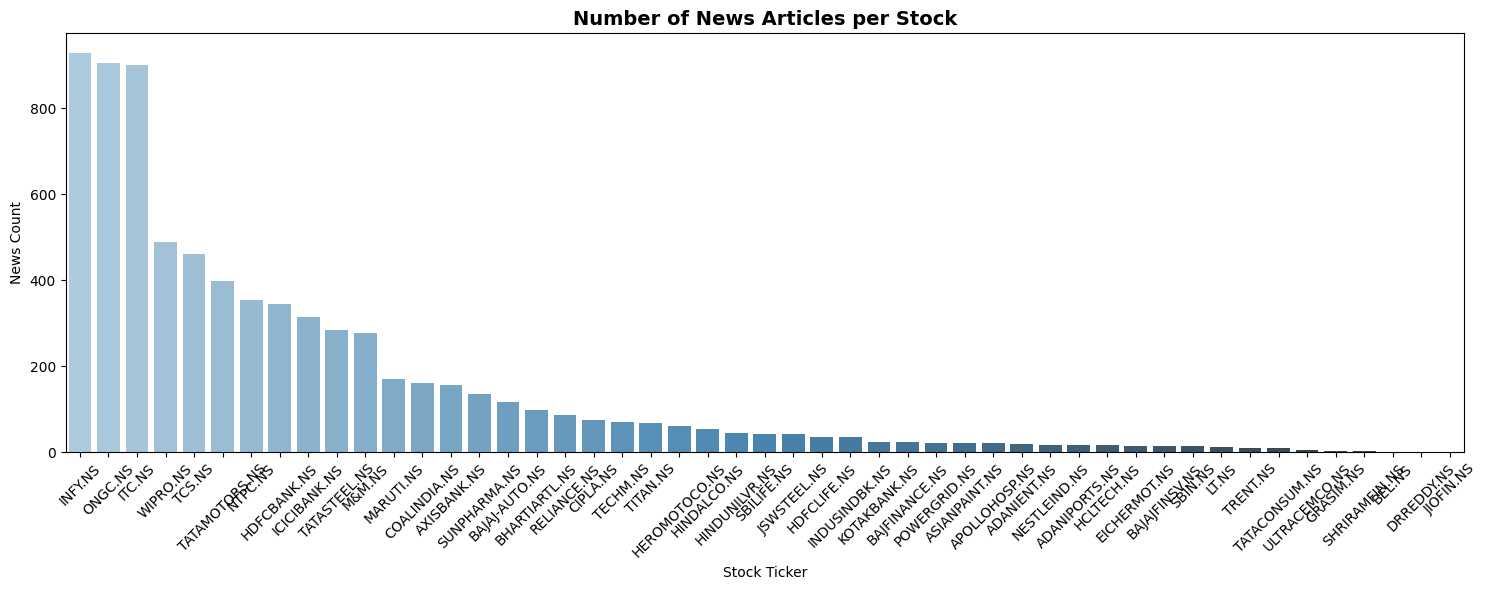

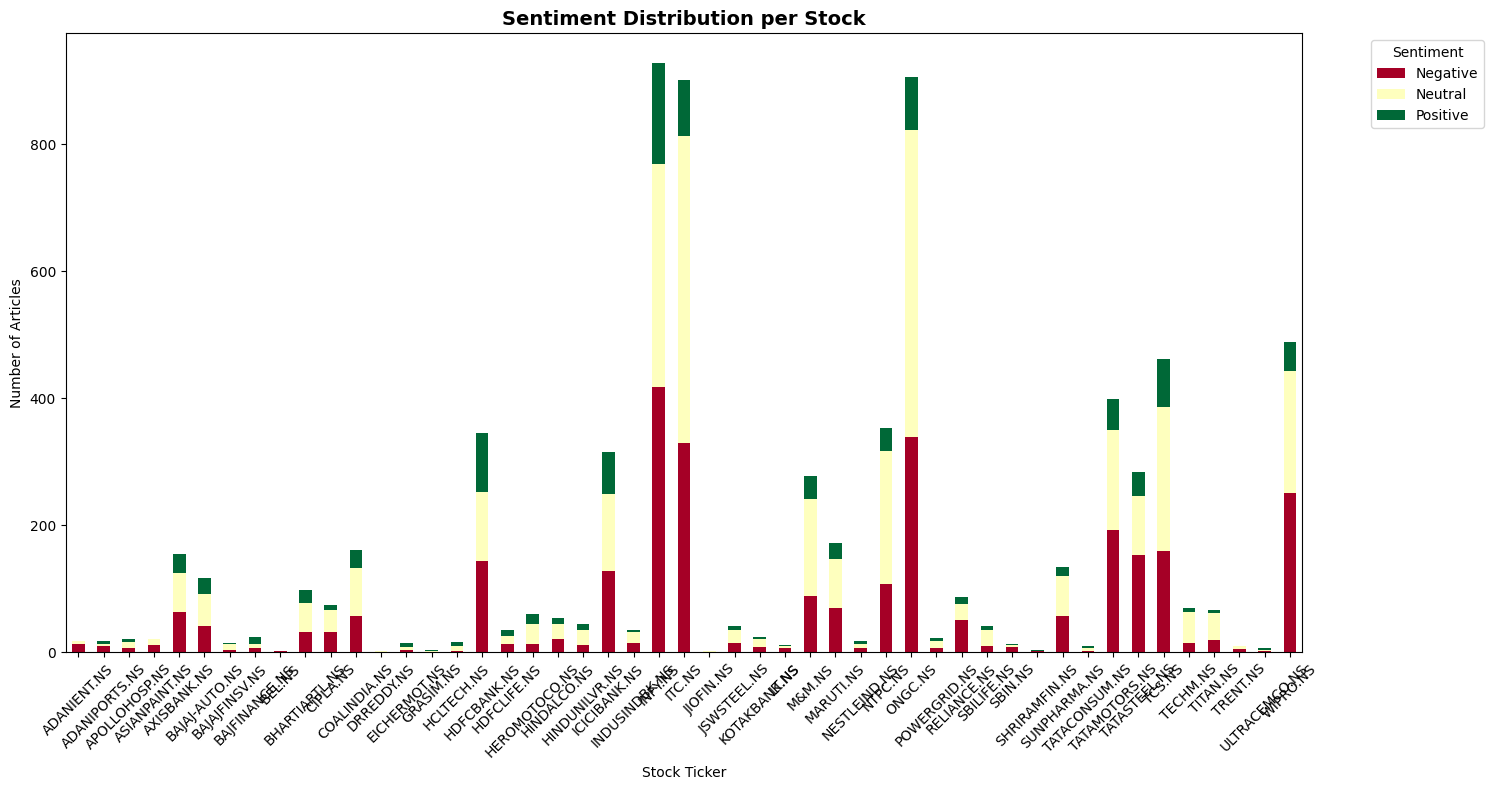

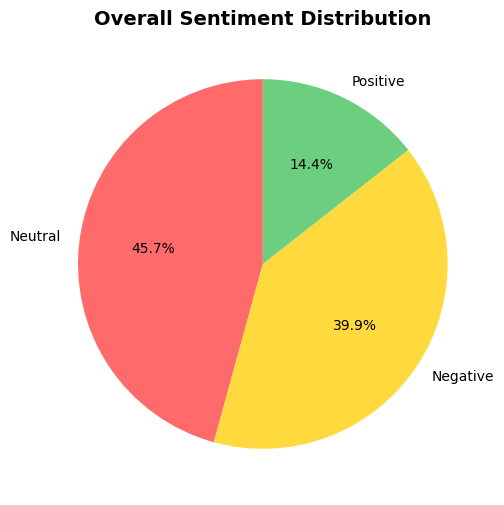


1 Failed download:
['ICICIBANK.NS']: DNSError('Failed to perform, curl: (6) Could not resolve host: query2.finance.yahoo.com. See https://curl.se/libcurl/c/libcurl-errors.html first for more details.')

1 Failed download:
['JIOFIN.NS']: YFPricesMissingError('possibly delisted; no price data found  (1d 2001-05-29 -> 2023-06-30) (Yahoo error = "Data doesn\'t exist for startDate = 991074600, endDate = 1688063400")')



9. Training XGBoost models...
Feature columns used for training:
['Close', 'High', 'Low', 'Open', 'Volume', 'avg_positive', 'avg_neutral', 'avg_negative', 'news_count', 'sentiment_std', 'SMA_5', 'SMA_10', 'SMA_20', 'EMA_12', 'EMA_26', 'RSI', 'MACD_12_26_9', 'MACDh_12_26_9', 'MACDs_12_26_9', 'BBL_20_2.0', 'BBM_20_2.0', 'BBU_20_2.0', 'BBB_20_2.0', 'BBP_20_2.0', 'OBV', 'VWAP', 'Returns', 'Log_Returns', 'High_Low_Ratio', 'Sentiment_Trend_3d', 'Sentiment_Trend_7d', 'Sentiment_Volatility', 'News_Volume_MA', 'News_Volume_Spike', 'Extreme_Positive', 'Extreme_Negative']
Training XGBoost models for 47 tickers...

--- Training model for: ADANIENT.NS ---
Test Accuracy: 0.4783 | F1: 0.4671
Model saved: xgboost_models\ADANIENT_xgboost_model.pkl

--- Training model for: ADANIPORTS.NS ---
Test Accuracy: 0.5210 | F1: 0.5099
Model saved: xgboost_models\ADANIPORTS_xgboost_model.pkl

--- Training model for: APOLLOHOSP.NS ---
Test Accuracy: 0.4882 | F1: 0.4752
Model saved: xgboost_models\APOLLOHOSP_xgboos

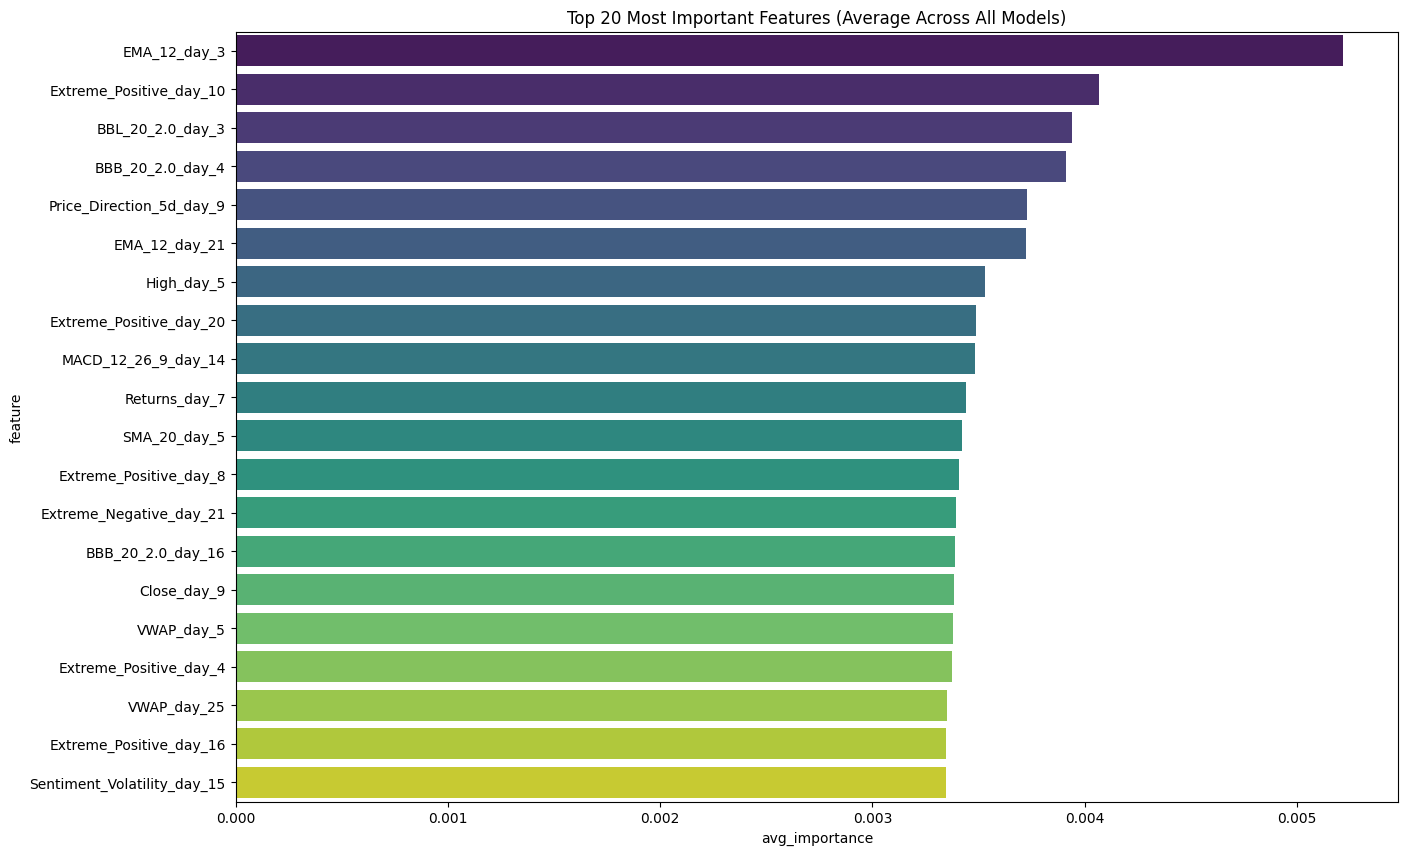

Feature importance analysis saved.

Pipeline completed successfully!


In [24]:
if __name__ == "__main__":
    results = main_pipeline_with_xgboost(
        model_choice="finbert-tone",
        retrain_finbert=False,
        train_xgboost=True,
        sequence_length=30
    )
    
    if len(results) == 5:
        featured_data, data_splits, model_manager, model_results, importance_df = results
        print(f"\nPipeline completed successfully!")